# Finding the Hidden Pulse

## Mathematical Detection of Natural Video Cut Points in Music

*Math Concepts for Developers — Final Project*

## 1. Introduction

As a creator of music videos, my work often requires choosing cut points that feel natural with the rhythm and structure of the music.

In music with strong transients, such as pronounced drum hits or sharp attacks, where the pacing is driven by high energy, suitable cut points may be relatively easy to identify. In smoother musical passages, however, natural editing points may follow a less obvious periodic pulse that is not represented by a single strong sound event.

My last project was of that kind. I spent days getting through the first half of a symphony, cutting again and again and replaying tiny fragments many times to find the right editing points. In the middle of the song, I realized that several consecutive clips had almost the same duration: 2 seconds and 20 frames (02:20 at 24 fps, approximately 2.83 s).

I decided to test this observation. I cut the next clip to the same duration without listening for a strong hit, without looking at the waveform, and without searching for an obvious peak. It fit naturally. I continued using the same interval and finished almost the entire second half of the video in about two hours, using this interval almost all the time, with few exceptions.

With this project, I will investigate whether simple mathematical analysis of an audio signal can detect these underlying rhythmic patterns and identify useful candidate points for video editing, potentially saving significant editing time and nerves.

### Research Question

Can a general mathematical method detect candidate cut points that align with manually selected edits across both strongly percussive and smooth musical passages?

### Project Scope

The project focuses on mathematical signal analysis.

The initial approach will examine:
- changes in local signal energy;
- repeated temporal patterns;
- periodicity in the audio signal;
- candidate cut points derived from these patterns.

The detected points will later be compared with manually selected edit points from real video projects.

## 2. Data and First Observation

The first experiment uses the track in which the original editing problem was observed.

During manual editing at 24 fps, several consecutive video clips naturally converged to a duration of 2 seconds and 20 frames:

\[
2 + \frac{20}{24} \approx 2.83 \text{ seconds}
\]

This observation suggests that the music may contain an underlying periodic structure near this interval.

The first goal is to inspect the audio signal and determine whether such a periodic pattern can be detected mathematically.

In [1]:
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt

sample_rate, audio = wavfile.read("data/earth.wav")

print("Sample rate:", sample_rate)
print("Shape:", audio.shape)
print("Duration:", len(audio) / sample_rate, "seconds")

Sample rate: 48000
Shape: (12432043, 2)
Duration: 259.00089583333335 seconds


C:\Users\Radev\AppData\Local\Temp\ipykernel_15644\4119837642.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read("data/earth.wav")


### 2.1 Representing the Audio Signal

Sound can be represented mathematically as an amplitude function of time:

$$
x(t)
$$

The WAV file is a sampled digital representation of this signal. With a sampling rate of

$$
f_s = 48000 \text{ Hz},
$$

the signal is represented by 48,000 measured amplitude values per second.

For sample index \(n\), the corresponding time is

$$
t_n = \frac{n}{f_s}.
$$

Therefore, the values stored in Python can be interpreted as samples of the underlying function:

$$
x(t_n).
$$

The WAV file contains two channels (stereo). For the initial analysis, the two channels are combined by taking their average, producing one amplitude value for each sampled point in time.

In [4]:
# Combine the stereo channels into one signal
audio_mono = audio.mean(axis=1).astype(np.float64)

# Normalize the amplitude to the interval [-1, 1]
x = audio_mono / np.max(np.abs(audio_mono))

# Create the corresponding time values
t = np.arange(len(x)) / sample_rate

print(f"Number of samples: {len(x)}")
print(f"Sampling rate: {sample_rate} Hz")
print(f"Duration: {t[-1]:.2f} seconds")

Number of samples: 12432043
Sampling rate: 48000 Hz
Duration: 259.00 seconds


### 2.2 Visualizing the Signal

The audio can now be viewed as an amplitude function of time:

$$
x(t).
$$

The complete recording contains more than twelve million samples. Plotting every sample is unnecessary for an overview, so a reduced number of points is used only for visualization. The original signal remains unchanged for the mathematical analysis.

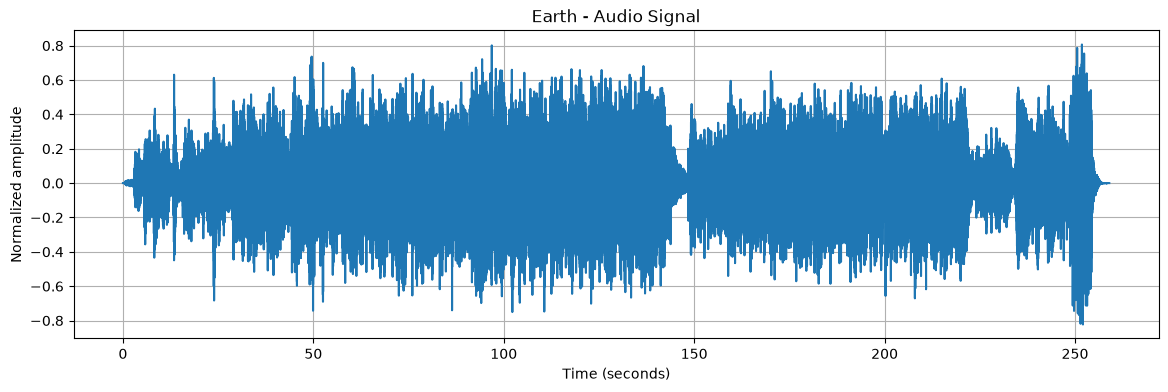

In [5]:
# Use fewer points only for plotting
target_points = 100_000
step = max(1, len(x) // target_points)

plt.figure(figsize=(14, 4))
plt.plot(t[::step], x[::step])

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("Earth - Audio Signal")
plt.grid()

plt.show()